<a href="https://colab.research.google.com/github/Handdyy11/Electricity_load_forecasting/blob/main/Electricity_forcasting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.weightstats import ztest
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

warnings.filterwarnings("ignore")              # hide non-critical warnings to keep output clean
sns.set_style("whitegrid")                     # clean plot style
plt.rcParams["figure.figsize"] = (12, 4)       # default plot size
pd.set_option("display.max_columns", 50)       # show all columns when printing tables

In [2]:
url = "https://raw.githubusercontent.com/Handdyy11/Electricity_load_forecasting/main/load_data.csv"
df = pd.read_csv(url)
df.head()

,datetime,nat_demand,T2M_toc,QV2M_toc,TQL_toc,W2M_toc,T2M_san,QV2M_san,TQL_san,W2M_san,T2M_dav,QV2M_dav,TQL_dav,W2M_dav,Holiday_ID,holiday,school
0,2015-01-03 01:00:00,970.3450,25.865259,0.018576,0.016174,21.850546,23.482446,0.017272,0.001855,10.328949,22.662134,0.016562,0.096100,5.364148,0,0,0
1,2015-01-03 02:00:00,912.1755,25.899255,0.018653,0.016418,22.166944,23.399255,0.017265,0.001327,10.681517,22.578943,0.016509,0.087646,5.572471,0,0,0
2,2015-01-03 03:00:00,900.2688,25.937280,0.018768,0.015480,22.454911,23.343530,0.017211,0.001428,10.874924,22.531030,0.016479,0.078735,5.871184,0,0,0
3,2015-01-03 04:00:00,889.9538,25.957544,0.018890,0.016273,22.110481,23.238794,0.017128,0.002599,10.518620,22.512231,0.016487,0.068390,5.883621,0,0,0
4,2015-01-03 05:00:00,893.6865,25.973840,0.018981,0.017281,21.186089,23.075403,0.017059,0.001729,9.733589,22.481653,0.016456,0.064362,5.611724,0,0,0


In [3]:
df.info()
print("Columns:", list(df.columns))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48048 entries, 0 to 48047
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   datetime    48048 non-null  object 
 1   nat_demand  48048 non-null  float64
 2   T2M_toc     48048 non-null  float64
 3   QV2M_toc    48048 non-null  float64
 4   TQL_toc     48048 non-null  float64
 5   W2M_toc     48048 non-null  float64
 6   T2M_san     48048 non-null  float64
 7   QV2M_san    48048 non-null  float64
 8   TQL_san     48048 non-null  float64
 9   W2M_san     48048 non-null  float64
 10  T2M_dav     48048 non-null  float64
 11  QV2M_dav    48048 non-null  float64
 12  TQL_dav     48048 non-null  float64
 13  W2M_dav     48048 non-null  float64
 14  Holiday_ID  48048 non-null  int64  
 15  holiday     48048 non-null  int64  
 16  school      48048 non-null  int64  
dtypes: float64(13), int64(3), object(1)
memory usage: 6.2+ MB
Columns: ['datetime', 'nat_demand', 'T2M_toc', 'Q

In [4]:
df["datetime"] = pd.to_datetime(df["datetime"])         # text -> real datetime type
df = df.sort_values("datetime").reset_index(drop=True)  # time series must be in time order

dups = df.duplicated(subset="datetime").sum()           # count repeated timestamps
print("Duplicate timestamps:", dups)
df = df.drop_duplicates(subset="datetime", keep="first").reset_index(drop=True)

print("Period:", df["datetime"].min(), "to", df["datetime"].max())
print("Rows  :", len(df))

Duplicate timestamps: 0
Period: 2015-01-03 01:00:00 to 2020-06-27 00:00:00
Rows  : 48048


In [5]:
missing = df.isna().sum()
print("Missing values per column:")
print(missing[missing > 0] if missing.sum() > 0 else "No missing values")

# A complete hourly timeline from first to last timestamp
full_range = pd.date_range(df["datetime"].min(), df["datetime"].max(), freq="h")
missing_hours = full_range.difference(df["datetime"])   # hours that should exist but do not
print("\nExpected hourly rows:", len(full_range))
print("Actual rows         :", len(df))
print("Missing hours       :", len(missing_hours))

Missing values per column:
No missing values

Expected hourly rows: 48048
Actual rows         : 48048
Missing hours       : 0


In [6]:
# The data has no missing values, no duplicates and no missing hours, so no filling is needed.
TARGET = "nat_demand"                                    # electricity load in MW (variable to forecast)
flag_cols = ["Holiday_ID", "holiday", "school"]          # calendar flags
weather_cols = [c for c in df.columns if c not in flag_cols + ["datetime", TARGET]]   # 12 weather variables

In [7]:
# Reported only, not removed - extreme load can be genuine
# IQR rule: a value is an outlier if it lies more than 1.5*IQR outside the quartiles
cols = [TARGET] + weather_cols
q1, q3 = df[cols].quantile(0.25), df[cols].quantile(0.75)
iqr = q3 - q1
n_out = ((df[cols] < q1 - 1.5 * iqr) | (df[cols] > q3 + 1.5 * iqr)).sum()
n_out.to_frame("n_outliers").assign(pct=(100 * n_out / len(df)).round(2))

,n_outliers,pct
nat_demand,7,0.01
T2M_toc,226,0.47
QV2M_toc,183,0.38
TQL_toc,850,1.77
W2M_toc,55,0.11
T2M_san,1292,2.69
QV2M_san,410,0.85
TQL_san,741,1.54
W2M_san,899,1.87
T2M_dav,889,1.85


In [8]:
print("Skewness of demand:", round(df[TARGET].skew(), 3))          # 0 = symmetric
df[cols].describe().T.round(3)                                     # mean, std, min, quartiles, max

Skewness of demand: 0.248


,count,mean,std,min,25%,50%,75%,max
nat_demand,48048.0,1182.869,192.069,85.193,1020.057,1168.428,1327.564,1754.882
T2M_toc,48048.0,27.399,1.675,22.953,26.160,27.118,28.558,35.040
QV2M_toc,48048.0,0.018,0.002,0.012,0.017,0.019,0.020,0.023
TQL_toc,48048.0,0.080,0.066,0.000,0.026,0.065,0.117,0.521
W2M_toc,48048.0,13.391,7.296,0.009,7.545,12.182,18.661,39.230
T2M_san,48048.0,26.921,3.018,19.765,24.769,26.167,28.712,39.063
QV2M_san,48048.0,0.018,0.002,0.010,0.017,0.018,0.019,0.022
TQL_san,48048.0,0.106,0.086,0.000,0.037,0.086,0.157,0.485
W2M_san,48048.0,7.047,4.104,0.060,3.955,5.993,9.410,24.484
T2M_dav,48048.0,24.720,2.414,19.934,22.955,24.002,26.243,34.216


In [9]:
df["hour"] = df["datetime"].dt.hour
df["dayofweek"] = df["datetime"].dt.dayofweek                      # 0 = Monday ... 6 = Sunday
df["month"] = df["datetime"].dt.month
df["is_weekend"] = (df["dayofweek"] >= 5).astype(int)              # 1 = Saturday/Sunday
df["season"] = np.where(df["month"].isin([1, 2, 3, 4]), "dry", "wet")   # Panama: dry Jan-Apr, wet May-Dec

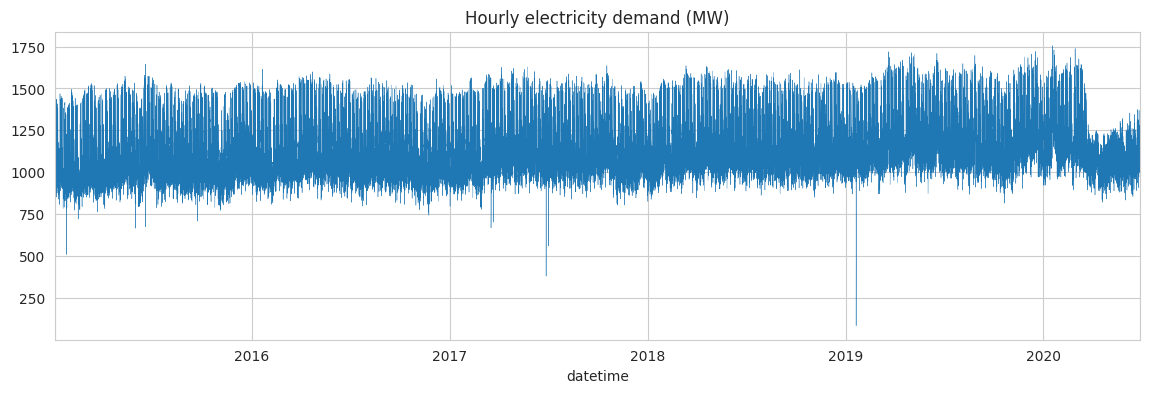

In [10]:
df.plot(x="datetime", y=TARGET, linewidth=0.3, figsize=(14, 4), legend=False, title="Hourly electricity demand (MW)")
plt.show()

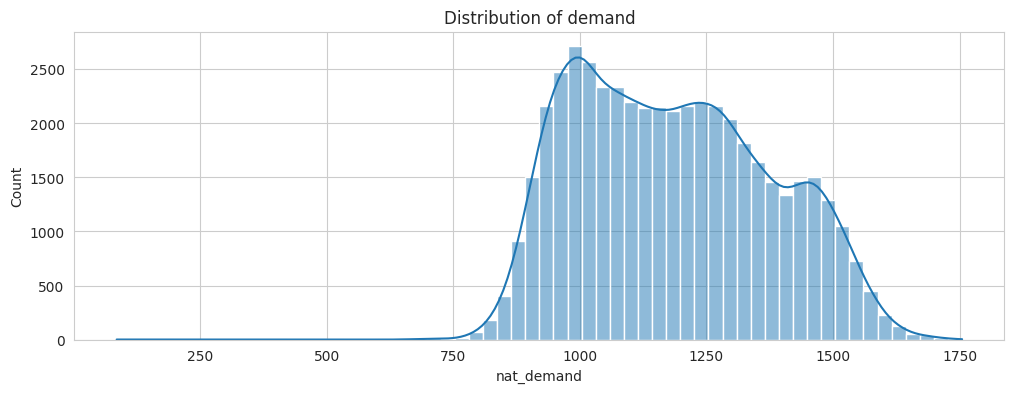

In [11]:
sns.histplot(df[TARGET], bins=60, kde=True)
plt.title("Distribution of demand")
plt.show()

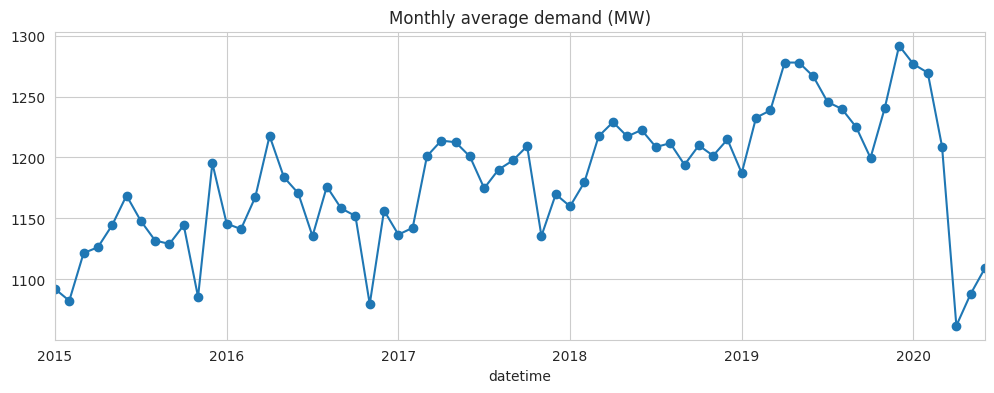

In [12]:
df.set_index("datetime")[TARGET].resample("MS").mean().plot(marker="o", title="Monthly average demand (MW)")
plt.show()

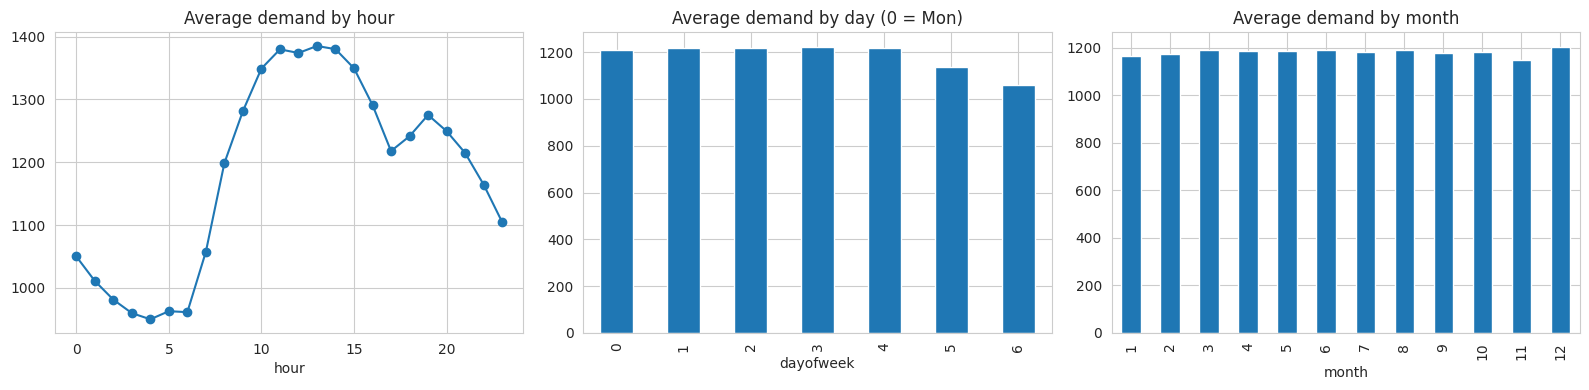

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
df.groupby("hour")[TARGET].mean().plot(ax=ax[0], marker="o", title="Average demand by hour")
df.groupby("dayofweek")[TARGET].mean().plot(kind="bar", ax=ax[1], title="Average demand by day (0 = Mon)")
df.groupby("month")[TARGET].mean().plot(kind="bar", ax=ax[2], title="Average demand by month")
plt.tight_layout(); plt.show()

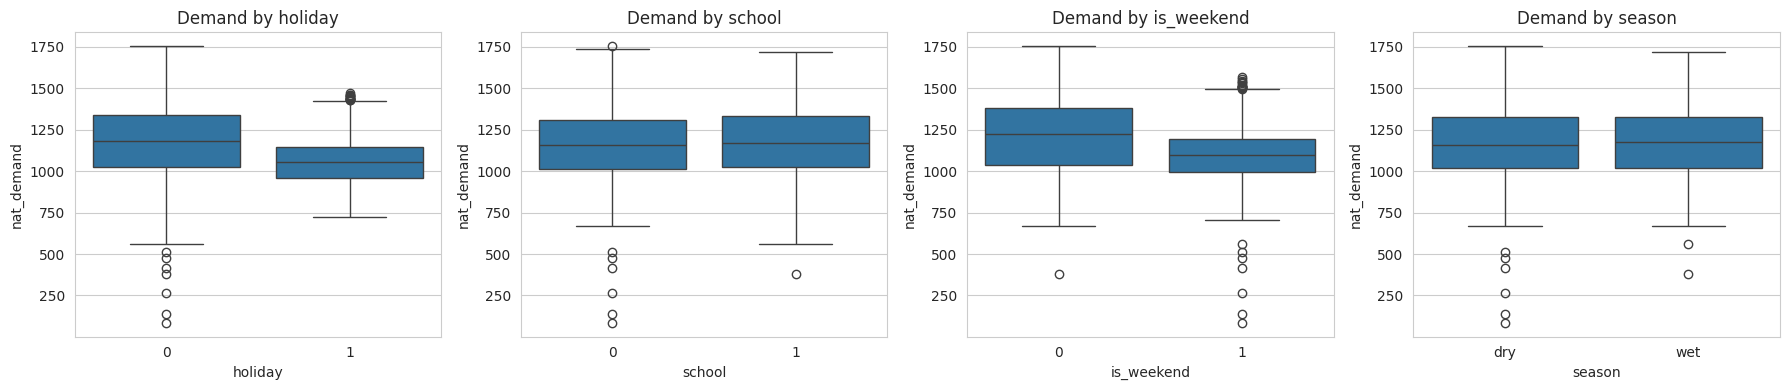

In [14]:
fig, ax = plt.subplots(1, 4, figsize=(18, 4))
for a, c in zip(ax, ["holiday", "school", "is_weekend", "season"]):
    sns.boxplot(x=c, y=TARGET, data=df, ax=a)
    a.set_title(f"Demand by {c}")
plt.tight_layout(); plt.show()

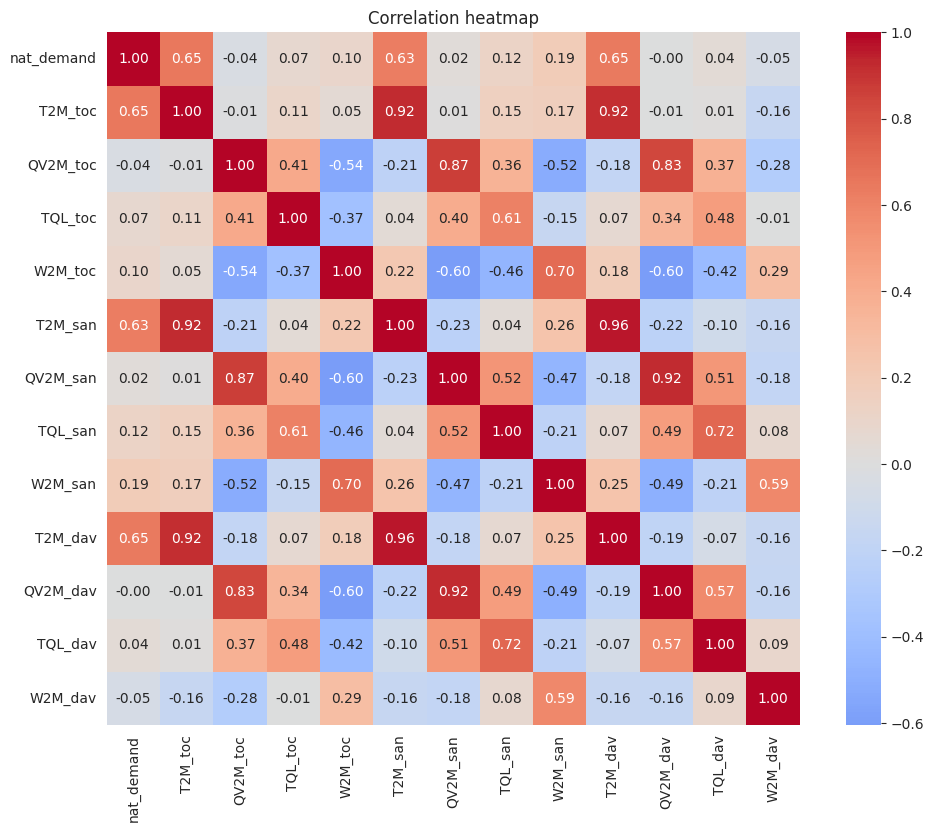

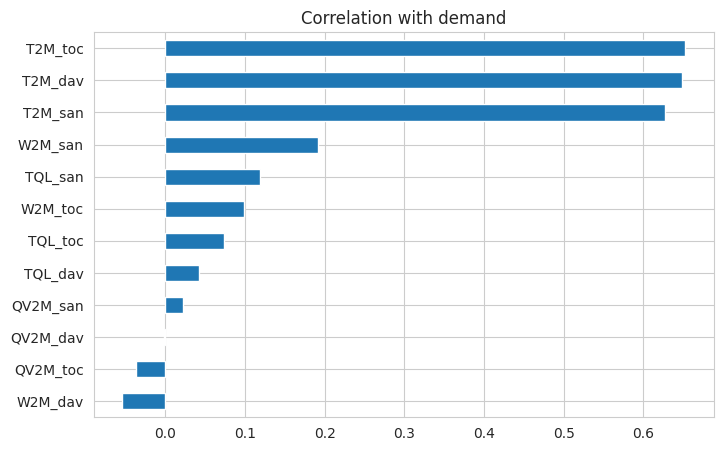

In [15]:
corr = df[cols].corr()

plt.figure(figsize=(12, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation heatmap")
plt.show()

corr[TARGET].drop(TARGET).sort_values().plot(kind="barh", figsize=(8, 5), title="Correlation with demand")
plt.show()

In [16]:
# shift(1) before rolling means the current hour is never used (no data leakage)
for h in (1, 24, 168):                                             # 1 hour, 1 day, 1 week ago
    df[f"lag_{h}"] = df[TARGET].shift(h)
for w in (24, 168):                                                # mean of previous day / week
    df[f"roll_mean_{w}"] = df[TARGET].shift(1).rolling(w).mean()
df = df.dropna().reset_index(drop=True)                            # first 168 rows have no lag_168

In [17]:
# Split by time, never shuffle a time series
df["set"] = np.where(df["datetime"] < "2020-01-01", "train", "test")
print(df["set"].value_counts())

set
train    43607
test      4273
Name: count, dtype: int64


In [18]:
# Then upload clean_data.csv to the repo's data/ folder
df.to_csv("clean_data.csv", index=False)
from google.colab import files
files.download("clean_data.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

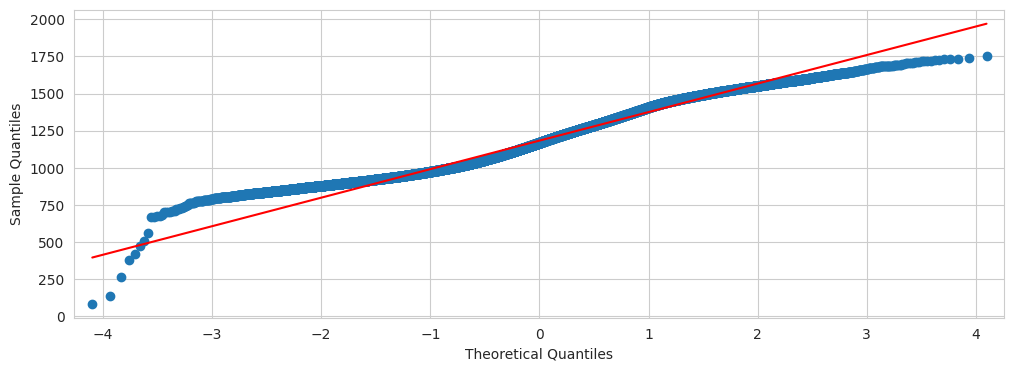

Normality test p-value: 1.9550069334368987e-86


In [19]:
import statsmodels.api as sm
# With ~48,000 rows the Central Limit Theorem makes mean-based tests reliable even if not perfectly normal
sm.qqplot(df[TARGET], line="s")                                    # points on the line = normal
plt.show()
print("Normality test p-value:", stats.normaltest(df[TARGET].sample(5000, random_state=42))[1])

In [20]:
# Welch t-test (does not assume equal variances). H0: mean demand is the same in both groups
p_vals = {}                                                        # collects p-values for the summary table
for col in ["holiday", "school"]:
    a, b = df.loc[df[col] == 1, TARGET], df.loc[df[col] == 0, TARGET]
    t, p = stats.ttest_ind(a, b, equal_var=False)
    p_vals[f"t-test: {col} vs not"] = p
    print(f"{col}: mean(1)={a.mean():.2f}, mean(0)={b.mean():.2f}, t={t:.3f}, p={p:.4g}")

holiday: mean(1)=1060.57, mean(0)=1191.38, t=-50.842, p=0
school: mean(1)=1187.57, mean(0)=1171.31, t=8.289, p=1.206e-16


In [21]:
# Two-sample z-test (valid because n is very large): dry vs wet season
dry = df.loc[df["season"] == "dry", TARGET]
wet = df.loc[df["season"] == "wet", TARGET]
z, p = ztest(dry, wet)
p_vals["z-test: dry vs wet"] = p
print(f"dry mean={dry.mean():.2f}, wet mean={wet.mean():.2f}, z={z:.3f}, p={p:.4g}")

dry mean=1181.63, wet mean=1184.05, z=-1.320, p=0.1868


In [22]:
# F = variance(dry) / variance(wet); H0: variances are equal
def f_test(x, y):
    F = np.var(x, ddof=1) / np.var(y, ddof=1)
    dfn, dfd = len(x) - 1, len(y) - 1
    return F, 2 * min(stats.f.cdf(F, dfn, dfd), stats.f.sf(F, dfn, dfd))   # two-tailed p-value

F, p = f_test(dry, wet)
p_vals["F-test: variance dry vs wet"] = p
print(f"F={F:.3f}, p={p:.4g}")

F=1.079, p=1.842e-08


In [23]:
F_a, p_a = stats.f_oneway(*[g[TARGET] for _, g in df.groupby("month")])   # do monthly means differ?
ols = sm.OLS(df[TARGET], sm.add_constant(df[weather_cols])).fit()         # do weather variables explain demand?
p_vals["ANOVA F-test: months"] = p_a
p_vals["Regression F-test: weather"] = ols.f_pvalue
print(f"ANOVA: F={F_a:.2f}, p={p_a:.4g}")
print(f"Regression: F={ols.fvalue:.2f}, p={ols.f_pvalue:.4g}, R-squared={ols.rsquared:.3f}")

ANOVA: F=20.31, p=1.254e-41
Regression: F=3480.52, p=0, R-squared=0.466


In [24]:
summary = pd.Series(p_vals, name="p-value").to_frame()
summary["Decision (5%)"] = np.where(summary["p-value"] < 0.05, "Reject H0", "Fail to reject H0")
summary

,p-value,Decision (5%)
t-test: holiday vs not,0.000000e+00,Reject H0
t-test: school vs not,1.206417e-16,Reject H0
z-test: dry vs wet,1.867865e-01,Fail to reject H0
F-test: variance dry vs wet,1.841581e-08,Reject H0
ANOVA F-test: months,1.253923e-41,Reject H0
Regression F-test: weather,0.000000e+00,Reject H0


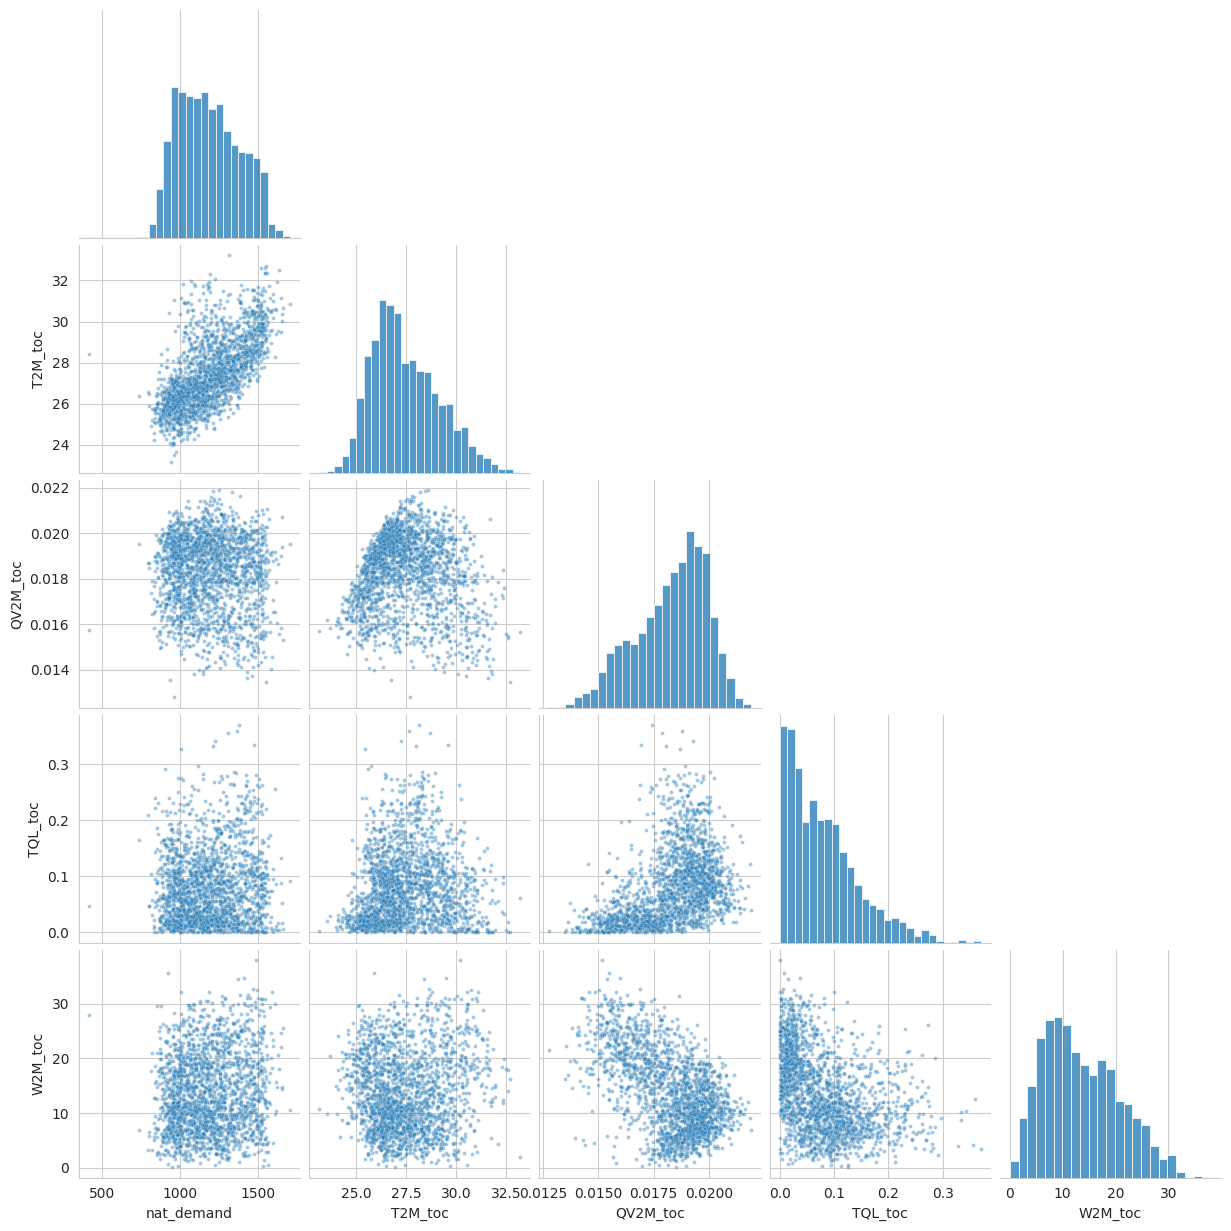

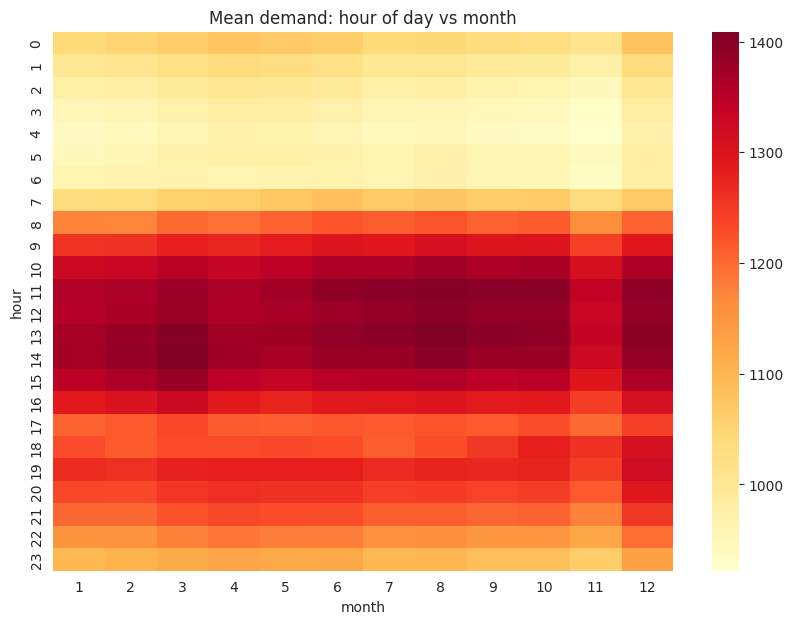

In [25]:
sns.pairplot(df[[TARGET] + weather_cols[:4]].sample(2000, random_state=1), corner=True, plot_kws={"s": 8, "alpha": 0.4})
plt.show()

plt.figure(figsize=(10, 7))
sns.heatmap(df.pivot_table(values=TARGET, index="hour", columns="month", aggfunc="mean"), cmap="YlOrRd")
plt.title("Mean demand: hour of day vs month")
plt.show()

Components needed for 95% variance: 7 of 12


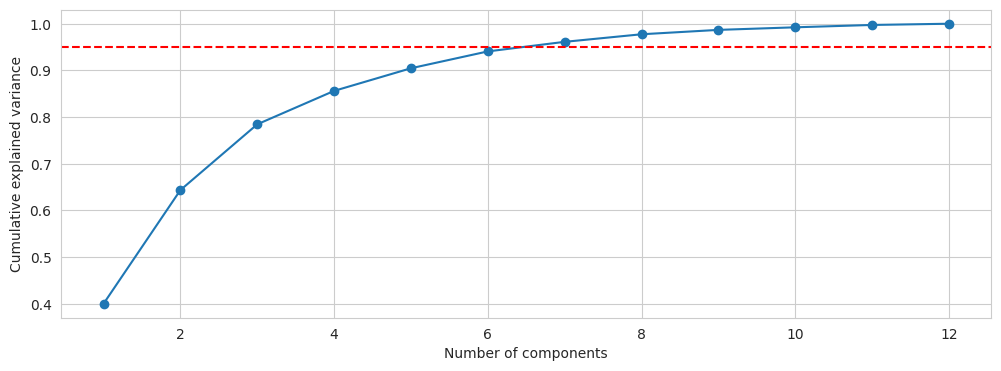

In [26]:
X = StandardScaler().fit_transform(df[weather_cols])               # standardise: PCA is scale-sensitive
pca = PCA().fit(X)
cum = pca.explained_variance_ratio_.cumsum()                       # cumulative explained variance
n95 = int(np.argmax(cum >= 0.95)) + 1
print(f"Components needed for 95% variance: {n95} of {len(weather_cols)}")

plt.plot(range(1, len(cum) + 1), cum, marker="o")
plt.axhline(0.95, color="r", linestyle="--")
plt.xlabel("Number of components"); plt.ylabel("Cumulative explained variance")
plt.show()

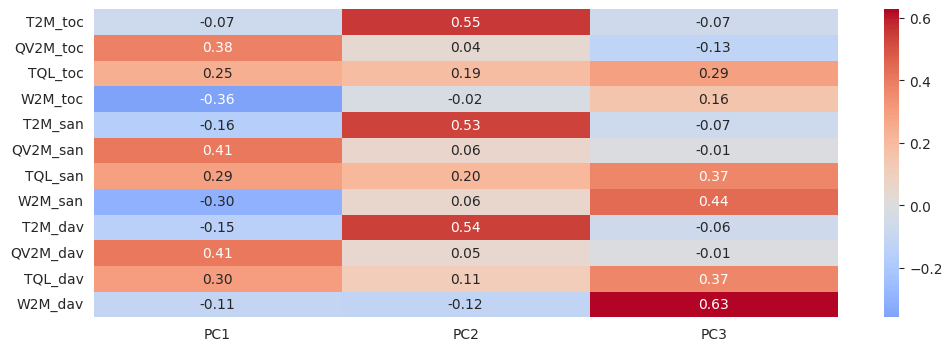

PC1   -0.126
PC2    0.645
PC3    0.017
dtype: float64


In [27]:
loadings = pd.DataFrame(pca.components_[:3].T, index=weather_cols, columns=["PC1", "PC2", "PC3"])
sns.heatmap(loadings, annot=True, fmt=".2f", cmap="coolwarm", center=0)   # which variables build each component
plt.show()

scores = pd.DataFrame(pca.transform(X)[:, :3], columns=["PC1", "PC2", "PC3"])
print(scores.corrwith(df[TARGET]).round(3))                        # correlation of each component with demand

In [28]:
#Anlesha's Part

In [29]:
#FORECASTING PART
#Converts hourly electricity demand into daily totals and removes incomplete days.
import pandas as pd
import matplotlib.pyplot as plt

# Convert datetime column
df["datetime"] = pd.to_datetime(df["datetime"])

# Create daily total electricity demand
daily_df = (
    df.sort_values("datetime")
      .set_index("datetime")["nat_demand"]
      .resample("D")
      .sum(min_count=24)
      .rename("daily_demand")
      .to_frame()
)

# Keep only complete days
daily_complete = daily_df.dropna(subset=["daily_demand"]).copy()

print("Daily dataframe shape:", daily_complete.shape)
print("First date:", daily_complete.index.min())
print("Last date:", daily_complete.index.max())
print("Missing daily totals:", daily_complete["daily_demand"].isna().sum())

Daily dataframe shape: (1994, 1)
First date: 2015-01-11 00:00:00
Last date: 2020-06-26 00:00:00
Missing daily totals: 0


Dates with missing daily totals:


,daily_demand
datetime,
2015-01-10,NaN
2020-06-27,NaN


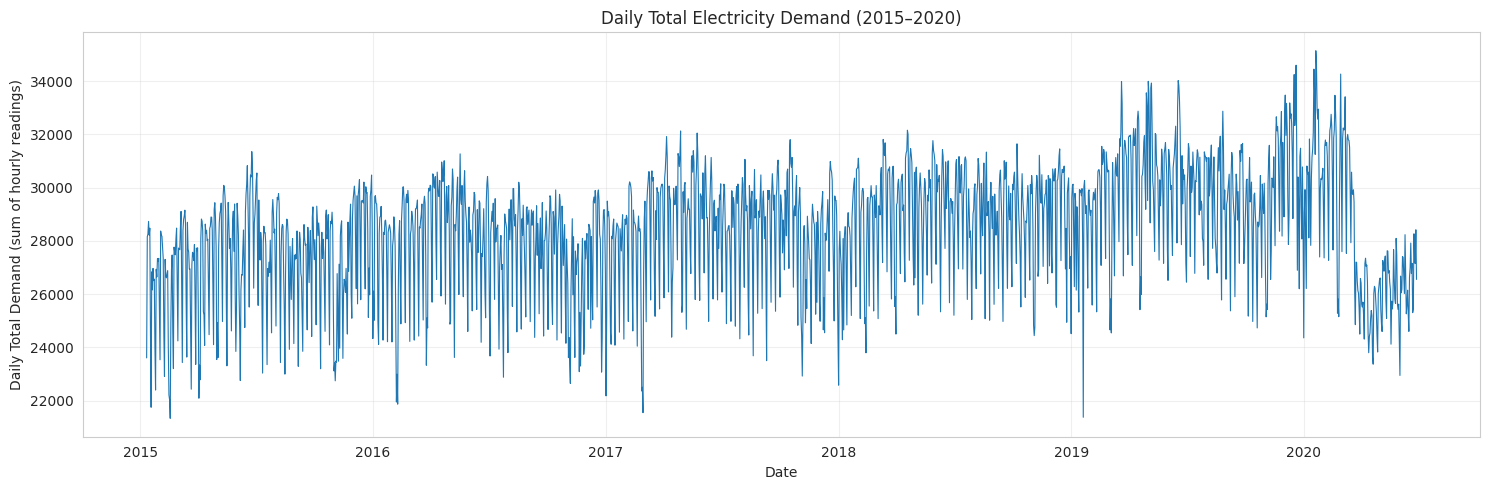

Number of valid daily totals: 1994
Minimum daily total: 21332.97
Maximum daily total: 35143.85
Average daily total: 28398.37


In [30]:
#Plots daily electricity demand and displays basic statistics such as minimum, maximum, and average demand.
import pandas as pd
import matplotlib.pyplot as plt

# Check missing daily totals
missing_dates = daily_df[daily_df["daily_demand"].isna()]
print("Dates with missing daily totals:")
display(missing_dates)

# Plot daily total demand
plot_df = daily_df.dropna(subset=["daily_demand"])

plt.figure(figsize=(15, 5))
plt.plot(
    plot_df.index,
    plot_df["daily_demand"],
    linewidth=0.8
)

plt.title("Daily Total Electricity Demand (2015–2020)")
plt.xlabel("Date")
plt.ylabel("Daily Total Demand (sum of hourly readings)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Basic statistics
print("Number of valid daily totals:", len(plot_df))
print("Minimum daily total:", round(plot_df["daily_demand"].min(), 2))
print("Maximum daily total:", round(plot_df["daily_demand"].max(), 2))
print("Average daily total:", round(plot_df["daily_demand"].mean(), 2))


In [31]:
#ADF stationarity test at the 5% significance level, so we do not need to apply first-order differencing automatically.
from statsmodels.tsa.stattools import adfuller

# Use the cleaned daily total demand series
daily_series = daily_complete["daily_demand"].astype(float)

# Run the ADF test
adf_result = adfuller(daily_series, autolag="AIC")

print("ADF Statistic:", round(adf_result[0], 4))
print("p-value:", round(adf_result[1], 6))
print("Number of lags used:", adf_result[2])
print("Number of observations:", adf_result[3])

print("\nCritical values:")
for key, value in adf_result[4].items():
    print(f"{key}: {value:.4f}")

if adf_result[1] < 0.05:
    print("\nConclusion: Reject the null hypothesis at the 5% level.")
    print("The ADF test provides evidence of stationarity.")
else:
    print("\nConclusion: Fail to reject the null hypothesis at the 5% level.")
    print("The ADF test does not provide sufficient evidence of stationarity.")


ADF Statistic: -3.529
p-value: 0.007273
Number of lags used: 26
Number of observations: 1967

Critical values:
1%: -3.4337
5%: -2.8630
10%: -2.5676

Conclusion: Reject the null hypothesis at the 5% level.
The ADF test provides evidence of stationarity.


Total daily records: 1994
Training records: 1595
Testing records: 399

Training period:
2015-01-11 00:00:00 to 2019-05-24 00:00:00

Testing period:
2019-05-25 00:00:00 to 2020-06-26 00:00:00


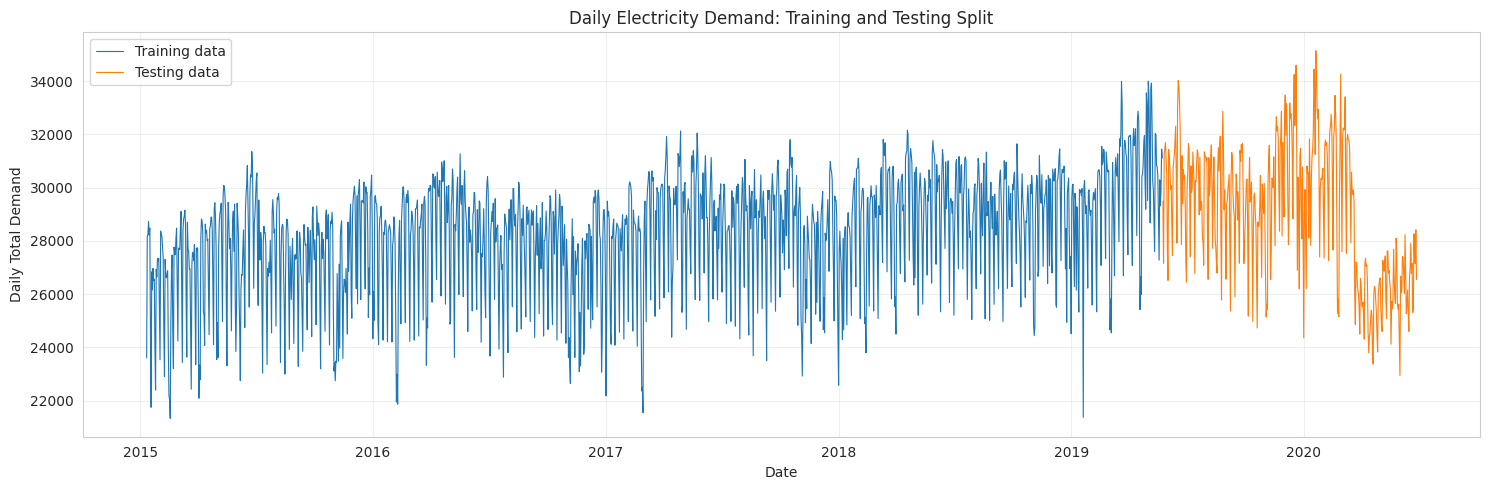

In [32]:

# Chronological train-test split for daily forecasting
daily_series = daily_complete["daily_demand"].astype(float).sort_index()

split_idx = int(len(daily_series) * 0.80)

train_daily = daily_series.iloc[:split_idx]
test_daily = daily_series.iloc[split_idx:]

print("Total daily records:", len(daily_series))
print("Training records:", len(train_daily))
print("Testing records:", len(test_daily))

print("\nTraining period:")
print(train_daily.index.min(), "to", train_daily.index.max())

print("\nTesting period:")
print(test_daily.index.min(), "to", test_daily.index.max())

# Visualize the split
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 5))
plt.plot(train_daily.index, train_daily, label="Training data", linewidth=0.8)
plt.plot(test_daily.index, test_daily, label="Testing data", linewidth=0.8)

plt.title("Daily Electricity Demand: Training and Testing Split")
plt.xlabel("Date")
plt.ylabel("Daily Total Demand")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


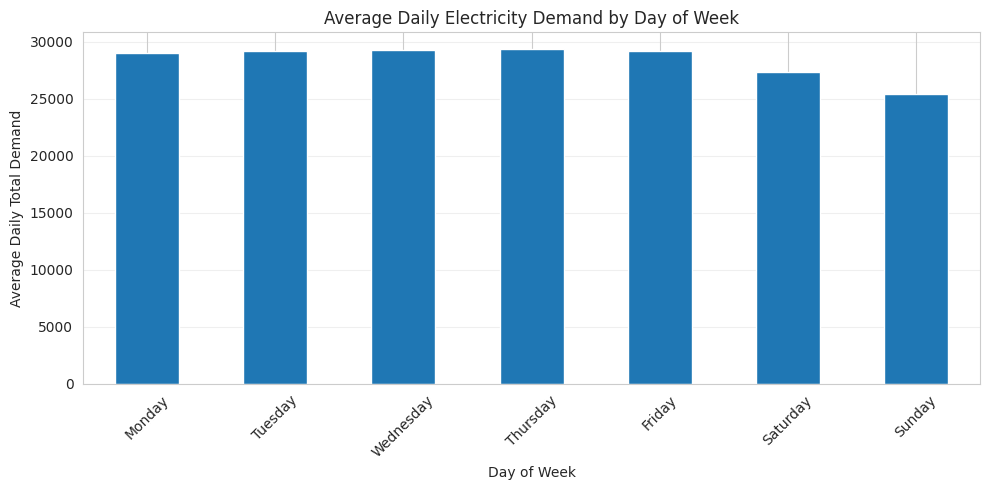

,Average Daily Demand
Monday,29001.033982
Tuesday,29198.958996
Wednesday,29261.080696
Thursday,29366.424249
Friday,29236.237640
Saturday,27338.521854
Sunday,25382.634621


In [33]:

import matplotlib.pyplot as plt

# Average demand for each day of the week
weekday_pattern = (
    daily_complete.assign(
        day_of_week=daily_complete.index.dayofweek
    )
    .groupby("day_of_week")["daily_demand"]
    .mean()
)

weekday_names = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

weekday_pattern.index = weekday_names

plt.figure(figsize=(10, 5))
weekday_pattern.plot(kind="bar")

plt.title("Average Daily Electricity Demand by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Average Daily Total Demand")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

display(weekday_pattern.to_frame("Average Daily Demand"))


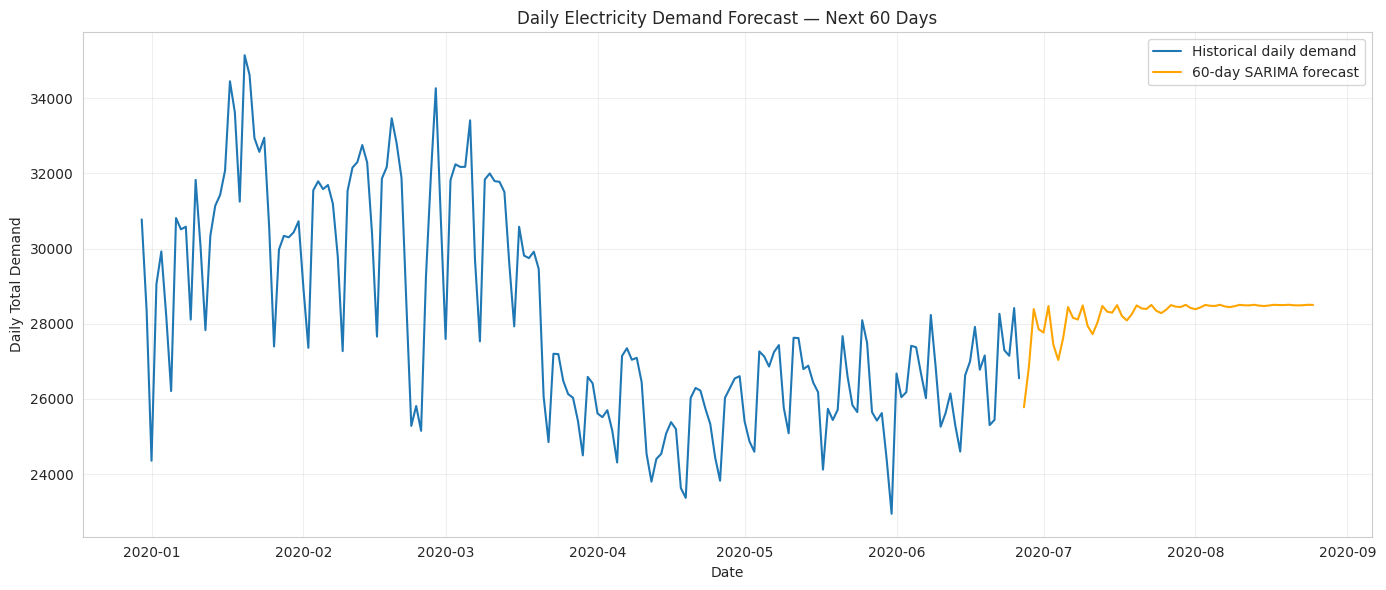

,Forecast Daily Demand
2020-06-27,25778.175319
2020-06-28,26841.863794
2020-06-29,28390.358057
2020-06-30,27855.475024
2020-07-01,27765.938398
2020-07-02,28471.730726
2020-07-03,27444.559649
2020-07-04,27036.821078
2020-07-05,27619.158376
2020-07-06,28444.370401


In [38]:

from statsmodels.tsa.statespace.sarimax import SARIMAX
import matplotlib.pyplot as plt
import pandas as pd

# Use all complete daily observations
series = daily_complete["daily_demand"].astype(float).sort_index()

# SARIMA with weekly seasonality
model = SARIMAX(
    series,
    order=(1, 0, 1),
    seasonal_order=(1, 0, 1, 7),
    trend="c",
    enforce_stationarity=False,
    enforce_invertibility=False
)

model_fit = model.fit(disp=False)

# Forecast next 60 days
forecast_result = model_fit.get_forecast(steps=60)
forecast = forecast_result.predicted_mean

forecast_dates = pd.date_range(
    start=series.index[-1] + pd.Timedelta(days=1),
    periods=60,
    freq="D"
)
forecast.index = forecast_dates

# Plot recent history and forecast
plt.figure(figsize=(14, 6))
plt.plot(
    series.index[-180:], series.iloc[-180:],
    label="Historical daily demand"
)
plt.plot(
    forecast.index, forecast,
    label="60-day SARIMA forecast",
    color="orange"
)

plt.title("Daily Electricity Demand Forecast — Next 60 Days")
plt.xlabel("Date")
plt.ylabel("Daily Total Demand")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

display(forecast.to_frame("Forecast Daily Demand"))


In [39]:
#GA Part
import pandas as pd
import numpy as np
import random

# Define target and candidate features
target = "nat_demand"

X = df.drop(columns=[target, "datetime", "set"], errors="ignore")
y = df[target]

# Encode categorical features
X_ga = pd.get_dummies(
    X,
    columns=["season"],
    drop_first=False,
    dtype=int
)

print("Dataset shape:", df.shape)
print("Number of predictor features:", X_ga.shape[1])
print("Target variable:", target)
print("Missing values:", X_ga.isnull().sum().sum())

Dataset shape: (47880, 28)
Number of predictor features: 26
Target variable: nat_demand
Missing values: 0


In [40]:
# Chronological 64% / 16% / 20% split
n = len(X_ga)

train_end = int(n * 0.64)
val_end = int(n * 0.80)

X_train_ga = X_ga.iloc[:train_end]
y_train_ga = y.iloc[:train_end]

X_val_ga = X_ga.iloc[train_end:val_end]
y_val_ga = y.iloc[train_end:val_end]

X_test_ga = X_ga.iloc[val_end:]
y_test_ga = y.iloc[val_end:]

print("Training set:", X_train_ga.shape, y_train_ga.shape)
print("Validation set:", X_val_ga.shape, y_val_ga.shape)
print("Testing set:", X_test_ga.shape, y_test_ga.shape)

Training set: (30643, 26) (30643,)
Validation set: (7661, 26) (7661,)
Testing set: (9576, 26) (9576,)


In [41]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
import numpy as np

def evaluate_features(individual):
    # Select features represented by 1
    selected = [
        col for col, gene in zip(X_train_ga.columns, individual)
        if gene == 1
    ]

    # Reject an empty feature subset
    if len(selected) == 0:
        return (1e10,)

    # Train on training data
    model = LinearRegression()
    model.fit(X_train_ga[selected], y_train_ga)

    # Evaluate on validation data
    predictions = model.predict(X_val_ga[selected])
    rmse = np.sqrt(mean_squared_error(y_val_ga, predictions))

    # Penalize larger feature subsets
    penalty = 0.1 * len(selected)
    fitness = rmse + penalty

    return (fitness,)

In [42]:
!pip install deap

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 93.1/93.1 kB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 879.5/879.5 kB 27.8 MB/s eta 0:00:00


In [43]:
import random
from deap import base, creator, tools, algorithms

random.seed(42)

if not hasattr(creator, "FitnessMin"):
    creator.create("FitnessMin", base.Fitness, weights=(-1.0,))

if not hasattr(creator, "Individual"):
    creator.create("Individual", list, fitness=creator.FitnessMin)

toolbox = base.Toolbox()

toolbox.register("gene", random.randint, 0, 1)
toolbox.register(
    "individual",
    tools.initRepeat,
    creator.Individual,
    toolbox.gene,
    n=X_train_ga.shape[1]
)
toolbox.register(
    "population",
    tools.initRepeat,
    list,
    toolbox.individual
)

toolbox.register("evaluate", evaluate_features)
toolbox.register("select", tools.selTournament, tournsize=3)
toolbox.register("mate", tools.cxTwoPoint)
toolbox.register("mutate", tools.mutFlipBit, indpb=0.05)

print("GA configuration completed.")
print("Number of candidate features:", X_train_ga.shape[1])
print("Selection: Tournament")
print("Crossover: Two-point")
print("Mutation: Bit-flip")

GA configuration completed.
Number of candidate features: 26
Selection: Tournament
Crossover: Two-point
Mutation: Bit-flip


In [44]:
# Initialize population
population = toolbox.population(n=20)

# Run Genetic Algorithm
population, logbook = algorithms.eaSimple(
    population,
    toolbox,
    cxpb=0.7,
    mutpb=0.2,
    ngen=10,
    verbose=True
)

# Get the best chromosome
best_individual = tools.selBest(population, k=1)[0]

# Extract selected features
ga_selected_features = [
    feature
    for feature, gene in zip(X_train_ga.columns, best_individual)
    if gene == 1
]

print("\nGA Feature Selection Results")
print("Total candidate features:", X_train_ga.shape[1])
print("Selected features:", len(ga_selected_features))
print("Excluded features:", X_train_ga.shape[1] - len(ga_selected_features))
print("Best fitness score:", round(best_individual.fitness.values[0], 4))
print("\nSelected feature names:")
for feature in ga_selected_features:
    print("-", feature)

gen	nevals
0  	20    
1  	15    
2  	13    
3  	11    
4  	17    
5  	12    
6  	17    
7  	12    
8  	13    
9  	19    
10 	18    

GA Feature Selection Results
Total candidate features: 26
Selected features: 15
Excluded features: 11
Best fitness score: 46.0479

Selected feature names:
- T2M_san
- QV2M_san
- TQL_san
- W2M_san
- T2M_dav
- QV2M_dav
- TQL_dav
- Holiday_ID
- holiday
- hour
- dayofweek
- lag_1
- lag_24
- lag_168
- roll_mean_24


In [45]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Train using only GA-selected features
ga_model = LinearRegression()
ga_model.fit(
    X_train_ga[ga_selected_features],
    y_train_ga
)

# Evaluate on the untouched test set
ga_predictions = ga_model.predict(
    X_test_ga[ga_selected_features]
)

ga_mae = mean_absolute_error(y_test_ga, ga_predictions)
ga_rmse = np.sqrt(mean_squared_error(y_test_ga, ga_predictions))

print("Final GA Evaluation")
print("Selected features:", len(ga_selected_features))
print("Test MAE:", round(ga_mae, 4))
print("Test RMSE:", round(ga_rmse, 4))

Final GA Evaluation
Selected features: 15
Test MAE: 34.2884
Test RMSE: 44.3767


In [46]:
# Save selected features
pd.DataFrame({
    "Selected Feature": ga_selected_features
}).to_csv("ga_selected_features.csv", index=False)

# Save evaluation metrics
ga_metrics = pd.DataFrame({
    "Method": ["GA + Linear Regression"],
    "Original Features": [X_ga.shape[1]],
    "Selected Features": [len(ga_selected_features)],
    "Test MAE": [ga_mae],
    "Test RMSE": [ga_rmse]
})

ga_metrics.to_csv("ga_evaluation_metrics.csv", index=False)

print("Selected features saved to ga_selected_features.csv")
print("\nFinal GA metrics:")
print(ga_metrics.to_string(index=False))

Selected features saved to ga_selected_features.csv

Final GA metrics:
                Method  Original Features  Selected Features  Test MAE  Test RMSE
GA + Linear Regression                 26                 15 34.288408  44.376693


In [47]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Baseline model using all features
baseline_model = LinearRegression()
baseline_model.fit(X_train_ga, y_train_ga)

baseline_predictions = baseline_model.predict(X_test_ga)

baseline_mae = mean_absolute_error(y_test_ga, baseline_predictions)
baseline_rmse = np.sqrt(
    mean_squared_error(y_test_ga, baseline_predictions)
)

print("Baseline (all 26 features)")
print("MAE:", round(baseline_mae, 4))
print("RMSE:", round(baseline_rmse, 4))

Baseline (all 26 features)
MAE: 34.2537
RMSE: 44.4812


In [48]:
# Laxmi's Part

In [61]:
# BLOCK 1: Prepare data for Mamdani FIS and PSO

# Use the 15 features selected by the Genetic Algorithm.
fis_candidate_features = list(ga_selected_features)
target = "nat_demand"

# Check that all required columns exist.
missing = [
    col for col in fis_candidate_features + [target]
    if col not in df.columns
]

if missing:
    raise ValueError(f"Missing columns in df: {missing}")

# Keep chronological order to prevent future-data leakage.
n = len(df)
train_end = int(n * 0.64)
val_end = int(n * 0.80)

# Training set: model construction and feature ranking.
X_train_fis_all = df[fis_candidate_features].iloc[:train_end].copy()
y_train_fis = df[target].iloc[:train_end].copy()

# Validation set: membership-function optimization and model selection.
X_val_fis_all = df[fis_candidate_features].iloc[train_end:val_end].copy()
y_val_fis = df[target].iloc[train_end:val_end].copy()

# Test set: reserved for final evaluation only.
X_test_fis_all = df[fis_candidate_features].iloc[val_end:].copy()
y_test_fis = df[target].iloc[val_end:].copy()

print("GA-selected candidate features:", len(fis_candidate_features))
print("Training records:", len(X_train_fis_all))
print("Validation records:", len(X_val_fis_all))
print("Test records:", len(X_test_fis_all))
print("Target:", target)

GA-selected candidate features: 15
Training records: 30643
Validation records: 7661
Test records: 9576
Target: nat_demand


In [62]:
# BLOCK 2: Set up the Mamdani FIS library

import importlib.util
import subprocess
import sys

# Install scikit-fuzzy only if it is not already available.
if importlib.util.find_spec("skfuzzy") is None:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "scikit-fuzzy"
    ])

# Import fuzzy logic tools.
import skfuzzy as fuzz
from skfuzzy import control as ctrl

print("scikit-fuzzy is ready.")

scikit-fuzzy is ready.


In [78]:
# BLOCK 3: Rank GA-selected features using training data

from sklearn.ensemble import RandomForestRegressor

# Train a model to estimate the relative importance of the 15 candidates.
importance_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=12,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

importance_model.fit(X_train_fis_all, y_train_fis)

# Rank features by their learned importance.
feature_importance = pd.DataFrame({
    "Feature": fis_candidate_features,
    "Importance": importance_model.feature_importances_
}).sort_values("Importance", ascending=False).reset_index(drop=True)

# Use the top six as the manageable Mamdani input set.
# This selection is data-driven, not a manually guessed list.
fis_features = feature_importance["Feature"].head(6).tolist()

# Create the reduced datasets for the fuzzy system.
X_train_fis = X_train_fis_all[fis_features].copy()
X_val_fis = X_val_fis_all[fis_features].copy()
X_test_fis = X_test_fis_all[fis_features].copy()

print("Feature importance ranking:")
print(feature_importance.to_string(index=False))

print("\nSelected six FIS features:")
print(fis_features)

Feature importance ranking:
     Feature  Importance
       lag_1    0.826216
     lag_168    0.105250
        hour    0.048887
      lag_24    0.006778
  Holiday_ID    0.003679
     holiday    0.002503
roll_mean_24    0.002109
   dayofweek    0.001841
     T2M_san    0.000537
     W2M_san    0.000499
     T2M_dav    0.000399
     TQL_san    0.000394
    QV2M_san    0.000318
    QV2M_dav    0.000296
     TQL_dav    0.000294

Selected six FIS features:
['lag_1', 'lag_168', 'hour', 'lag_24', 'Holiday_ID', 'holiday']


In [79]:
# FIX: Ensure all six updated features are selected before creating membership functions

fis_features = [
    "lag_1",
    "lag_168",
    "hour",
    "lag_24",
    "roll_mean_24",
    "holiday"
]

# Rebuild the FIS input datasets
X_train_fis = X_train_fis_all[fis_features].copy()
X_val_fis = X_val_fis_all[fis_features].copy()
X_test_fis = X_test_fis_all[fis_features].copy()

print("FIS features:", fis_features)
print("Training shape:", X_train_fis.shape)

FIS features: ['lag_1', 'lag_168', 'hour', 'lag_24', 'roll_mean_24', 'holiday']
Training shape: (30643, 6)


In [80]:
# BLOCK 4: Create trapezoidal membership functions for Mamdani FIS

fis_inputs = {}

for feature in fis_features:

    if feature == "holiday":
        # Binary feature: Non-Holiday and Holiday
        universe = np.linspace(0, 1, 101)
        fis_inputs[feature] = ctrl.Antecedent(universe, feature)

        fis_inputs[feature]["Non-Holiday"] = fuzz.trapmf(
            universe, [0, 0, 0.2, 0.5]
        )
        fis_inputs[feature]["Holiday"] = fuzz.trapmf(
            universe, [0.5, 0.8, 1, 1]
        )

    else:
        # Numerical features: Low, Medium, High
        values = X_train_fis[feature].to_numpy()
        minimum = values.min()
        maximum = values.max()

        if minimum == maximum:
            raise ValueError(f"{feature} has constant values.")

        span = maximum - minimum
        universe = np.linspace(minimum, maximum, 201)
        fis_inputs[feature] = ctrl.Antecedent(universe, feature)

        # Low: left-shoulder trapezoid
        fis_inputs[feature]["Low"] = fuzz.trapmf(
            universe,
            [minimum, minimum, minimum + 0.15 * span,
             minimum + 0.40 * span]
        )

        # Medium: trapezoid with a flat middle
        fis_inputs[feature]["Medium"] = fuzz.trapmf(
            universe,
            [minimum + 0.20 * span, minimum + 0.40 * span,
             minimum + 0.60 * span, minimum + 0.80 * span]
        )

        # High: right-shoulder trapezoid
        fis_inputs[feature]["High"] = fuzz.trapmf(
            universe,
            [minimum + 0.60 * span, minimum + 0.85 * span,
             maximum, maximum]
        )

# Define the electricity demand output
demand_min = y_train_fis.min()
demand_max = y_train_fis.max()
demand_span = demand_max - demand_min
demand_universe = np.linspace(demand_min, demand_max, 301)

fis_output = ctrl.Consequent(demand_universe, "nat_demand")

fis_output["Low"] = fuzz.trapmf(
    demand_universe,
    [demand_min, demand_min,
     demand_min + 0.20 * demand_span,
     demand_min + 0.40 * demand_span]
)

fis_output["Medium"] = fuzz.trapmf(
    demand_universe,
    [demand_min + 0.25 * demand_span,
     demand_min + 0.40 * demand_span,
     demand_min + 0.60 * demand_span,
     demand_min + 0.75 * demand_span]
)

fis_output["High"] = fuzz.trapmf(
    demand_universe,
    [demand_min + 0.60 * demand_span,
     demand_min + 0.80 * demand_span,
     demand_max, demand_max]
)

print("Trapezoidal membership functions created successfully.")
print("FIS inputs:", fis_features)
print("Output: nat_demand")

Trapezoidal membership functions created successfully.
FIS inputs: ['lag_1', 'lag_168', 'hour', 'lag_24', 'roll_mean_24', 'holiday']
Output: nat_demand


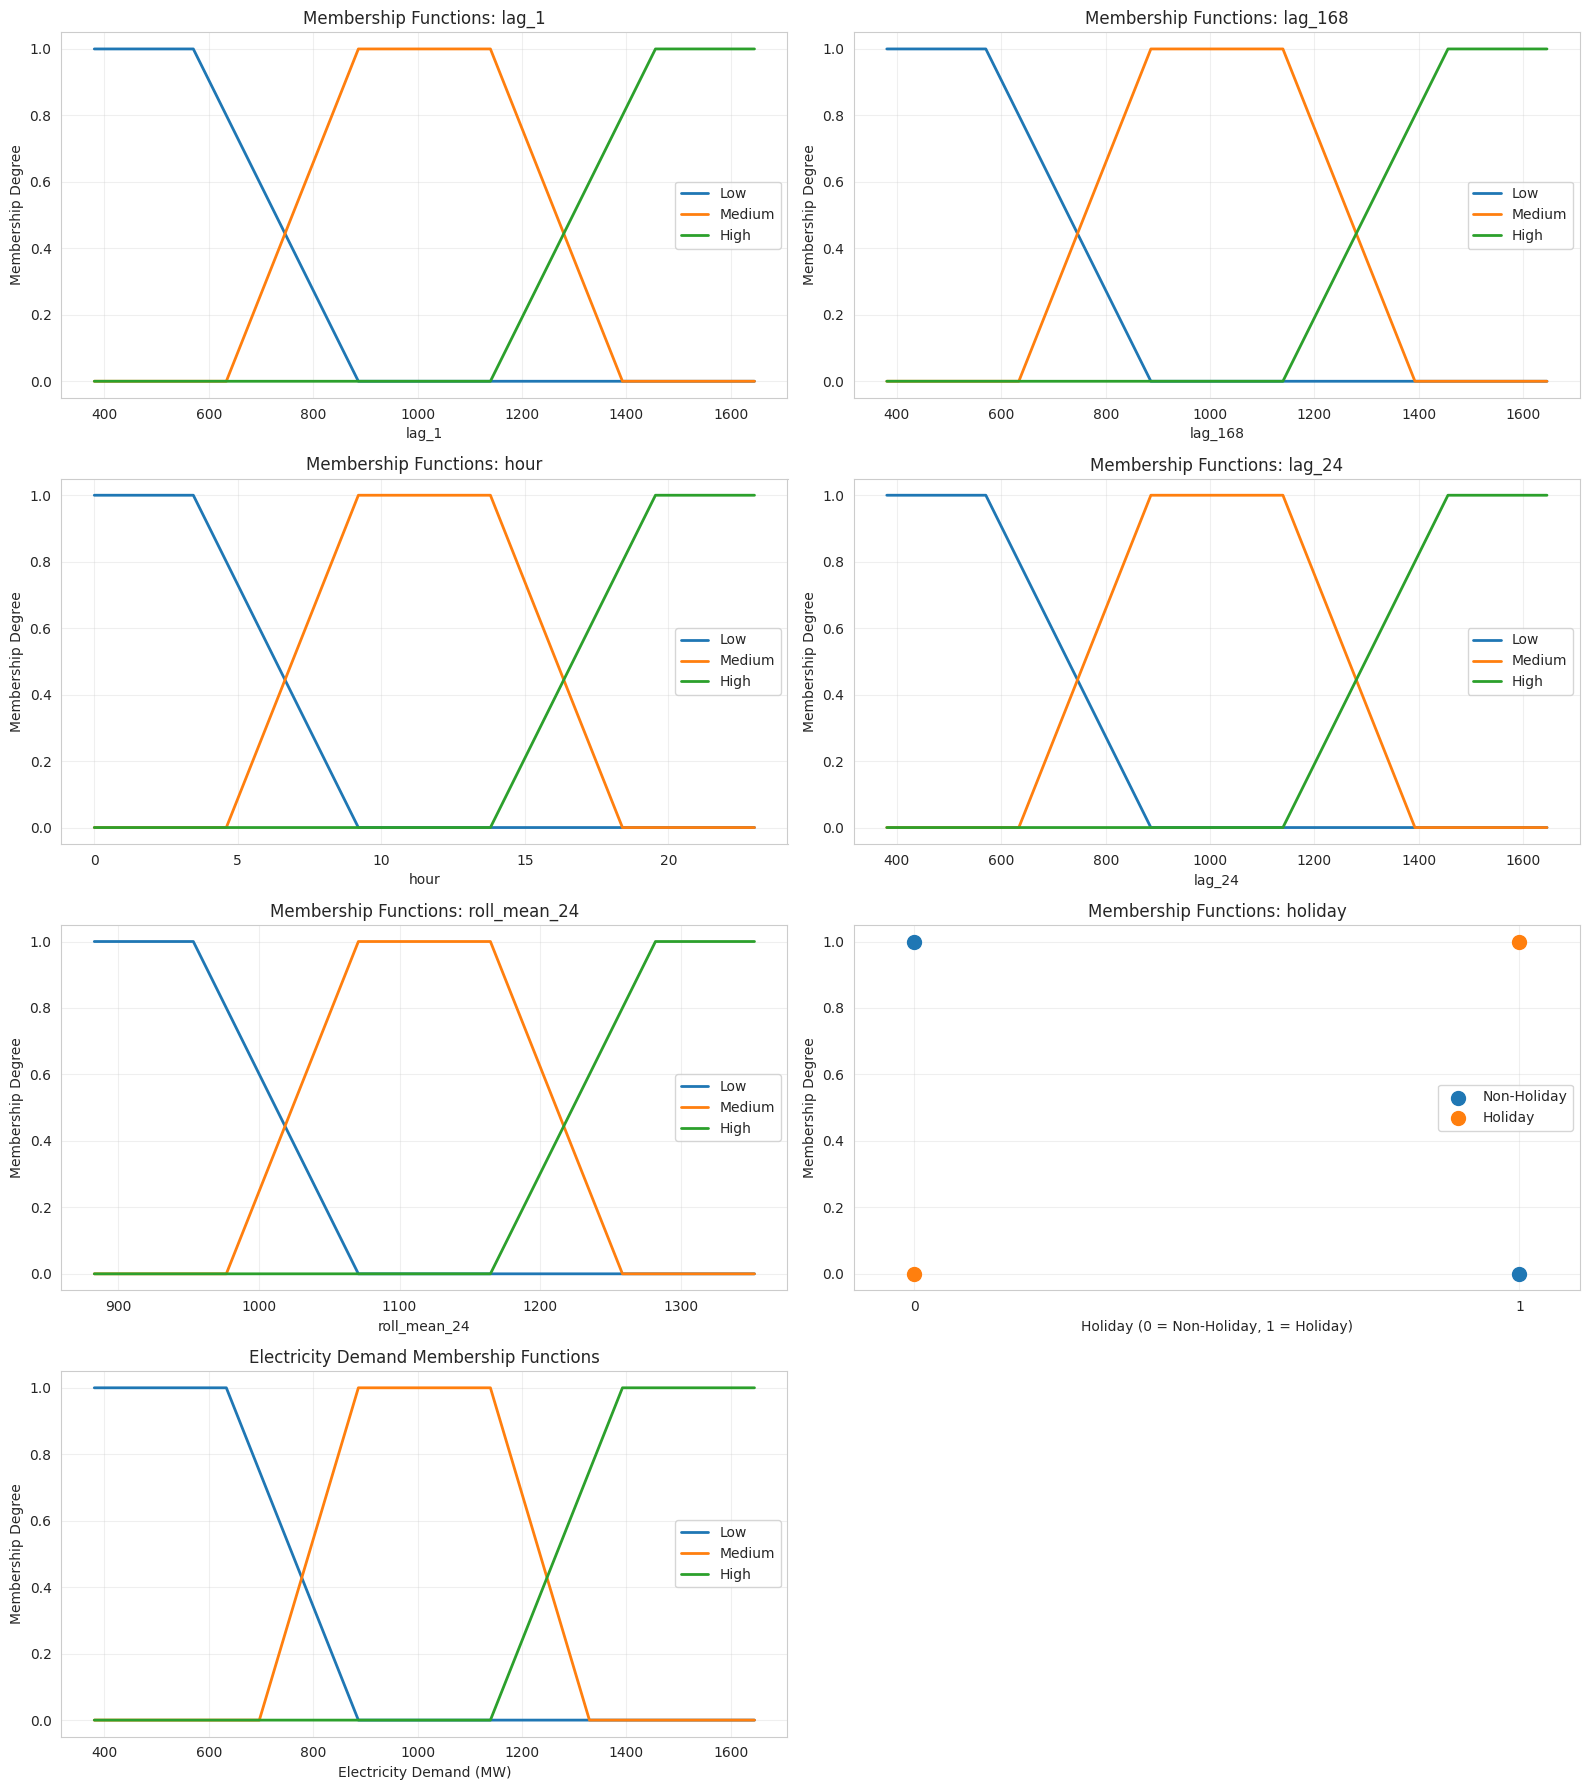

In [81]:
# BLOCK 4.1: Plot trapezoidal membership functions

fig, axes = plt.subplots(4, 2, figsize=(16, 18))
axes = axes.flatten()

# Plot membership functions for all six inputs
for i, feature in enumerate(fis_features):
    variable = fis_inputs[feature]

    # Holiday is binary, so plot only its two valid values
    if feature == "holiday":
        axes[i].scatter(
            [0, 1], [1, 0],
            label="Non-Holiday",
            s=100
        )
        axes[i].scatter(
            [0, 1], [0, 1],
            label="Holiday",
            s=100
        )

        axes[i].set_xticks([0, 1])
        axes[i].set_xlim(-0.1, 1.1)

    else:
        # Plot trapezoidal membership functions for numerical inputs
        for label, term in variable.terms.items():
            axes[i].plot(
                variable.universe,
                term.mf,
                label=label,
                linewidth=2
            )

    axes[i].set_title(f"Membership Functions: {feature}")
    axes[i].set_xlabel(
        "Holiday (0 = Non-Holiday, 1 = Holiday)"
        if feature == "holiday" else feature
    )
    axes[i].set_ylabel("Membership Degree")
    axes[i].set_ylim(-0.05, 1.05)
    axes[i].legend()
    axes[i].grid(True, alpha=0.3)

# Plot electricity demand output membership functions
for label, term in fis_output.terms.items():
    axes[6].plot(
        fis_output.universe,
        term.mf,
        label=label,
        linewidth=2
    )

axes[6].set_title("Electricity Demand Membership Functions")
axes[6].set_xlabel("Electricity Demand (MW)")
axes[6].set_ylabel("Membership Degree")
axes[6].set_ylim(-0.05, 1.05)
axes[6].legend()
axes[6].grid(True, alpha=0.3)

# Hide the unused subplot
axes[7].axis("off")

plt.tight_layout()
plt.show()

In [117]:
# BLOCK 5: Create 30 Mamdani FIS rules

fis_rules = []

# Rules 1–9: Combine previous-hour and previous-day demand
demand_combinations = [
    ("Low", "Low", "Low"),
    ("Low", "Medium", "Low"),
    ("Low", "High", "Medium"),
    ("Medium", "Low", "Low"),
    ("Medium", "Medium", "Medium"),
    ("Medium", "High", "High"),
    ("High", "Low", "Medium"),
    ("High", "Medium", "High"),
    ("High", "High", "High")
]

for lag1_level, lag24_level, output_level in demand_combinations:
    fis_rules.append(
        ctrl.Rule(
            fis_inputs["lag_1"][lag1_level] &
            fis_inputs["lag_24"][lag24_level],
            fis_output[output_level]
        )
    )

# Rules 10–12: Weekly demand influence
for level in ["Low", "Medium", "High"]:
    fis_rules.append(
        ctrl.Rule(
            fis_inputs["lag_168"][level],
            fis_output[level]
        )
    )

# Rules 13–15: Rolling average influence
for level in ["Low", "Medium", "High"]:
    fis_rules.append(
        ctrl.Rule(
            fis_inputs["roll_mean_24"][level],
            fis_output[level]
        )
    )

# Rules 16–18: Hour and previous-day demand
for hour_level, demand_level, output_level in [
    ("Low", "Low", "Low"),
    ("Medium", "Medium", "Medium"),
    ("High", "High", "High")
]:
    fis_rules.append(
        ctrl.Rule(
            fis_inputs["hour"][hour_level] &
            fis_inputs["lag_24"][demand_level],
            fis_output[output_level]
        )
    )

# Rules 19–21: Weekly and recent demand
for level in ["Low", "Medium", "High"]:
    fis_rules.append(
        ctrl.Rule(
            fis_inputs["lag_168"][level] &
            fis_inputs["lag_1"][level],
            fis_output[level]
        )
    )

# Rules 22–24: Rolling average and previous-day demand
for level in ["Low", "Medium", "High"]:
    fis_rules.append(
        ctrl.Rule(
            fis_inputs["roll_mean_24"][level] &
            fis_inputs["lag_24"][level],
            fis_output[level]
        )
    )

# Rules 25–27: Hour and recent demand
for level in ["Low", "Medium", "High"]:
    fis_rules.append(
        ctrl.Rule(
            fis_inputs["hour"][level] &
            fis_inputs["lag_1"][level],
            fis_output[level]
        )
    )

# Rules 28–30: Holiday and recent demand
for holiday_level, demand_level, output_level in [
    ("Holiday", "Low", "Low"),
    ("Holiday", "Medium", "Medium"),
    ("Non-Holiday", "High", "High")
]:
    fis_rules.append(
        ctrl.Rule(
            fis_inputs["holiday"][holiday_level] &
            fis_inputs["lag_1"][demand_level],
            fis_output[output_level]
        )
    )

# Verify rule count
print("Total FIS rules:", len(fis_rules))
assert len(fis_rules) == 30, "Expected exactly 30 rules."
print("All six input features are represented in the rules.")

Total FIS rules: 30
All six input features are represented in the rules.


In [118]:
# BLOCK 6: Rebuild the Mamdani FIS control system

# Recreate the control system from the latest rules
fis_control_system = ctrl.ControlSystem(fis_rules)
fis_simulation = ctrl.ControlSystemSimulation(fis_control_system)

print("FIS control system rebuilt.")
print("Rules:", len(fis_rules))
print("Features:", fis_features)

# Check which inputs the control system actually accepts
accepted_inputs = [
    antecedent.label
    for antecedent in fis_control_system.antecedents
]

print("Accepted inputs:", accepted_inputs)

FIS control system rebuilt.
Rules: 30
Features: ['lag_1', 'lag_168', 'hour', 'lag_24', 'roll_mean_24', 'holiday']
Accepted inputs: ['lag_1', 'lag_24', 'lag_168', 'roll_mean_24', 'hour', 'holiday']


In [ ]:
# BLOCK 7: Generate FIS validation predictions

fis_simulation = ctrl.ControlSystemSimulation(fis_control_system)

fis_predictions = []
failed_predictions = 0
first_error = None

for i in range(len(X_val_fis)):
    try:
        # Supply all six input features
        for feature in fis_features:
            fis_simulation.input[feature] = float(X_val_fis.iloc[i][feature])

        fis_simulation.compute()
        fis_predictions.append(fis_simulation.output["nat_demand"])

    except Exception as e:
        fis_predictions.append(np.nan)
        failed_predictions += 1

        if first_error is None:
            first_error = f"{type(e).__name__}: {e}"

fis_predictions = np.array(fis_predictions, dtype=float)
actual_values = y_val_fis.to_numpy(dtype=float)

valid = np.isfinite(fis_predictions) & np.isfinite(actual_values)

print("Total validation samples:", len(X_val_fis))
print("Valid predictions:", valid.sum())
print("Failed predictions:", failed_predictions)

if first_error:
    print("First error:", first_error)

if valid.sum() > 0:
    print("First five predictions:", fis_predictions[valid][:5])
else:
    print("No valid predictions. We need to fix the error before plotting.")

fis_val_mae = mean_absolute_error(actual_values[valid], fis_predictions[valid])

fis_val_rmse = np.sqrt(
    mean_squared_error(actual_values[valid], fis_predictions[valid])
)

print(f"FIS Validation MAE:  {fis_val_mae:.4f} MW")
print(f"FIS Validation RMSE: {fis_val_rmse:.4f} MW")

In [ ]:
# BLOCK 8: Visualize FIS predictions against actual demand

# Use only valid predictions for plotting
valid_indices = np.where(valid)[0]

plt.figure(figsize=(15, 6))

plt.plot(
    actual_values[valid],
    label="Actual Demand",
    linewidth=1.5
)

plt.plot(
    fis_predictions[valid],
    label="FIS Predicted Demand",
    linewidth=1.5
)

plt.title("Mamdani FIS: Actual vs Predicted Electricity Demand")
plt.xlabel("Validation Sample")
plt.ylabel("Electricity Demand (MW)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()